Device: cpu


100%|██████████| 9.91M/9.91M [00:00<00:00, 21.8MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 537kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.93MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 8.32MB/s]


Epoch 1, Loss: 409.29
Epoch 2, Loss: 246.10
Epoch 3, Loss: 220.90


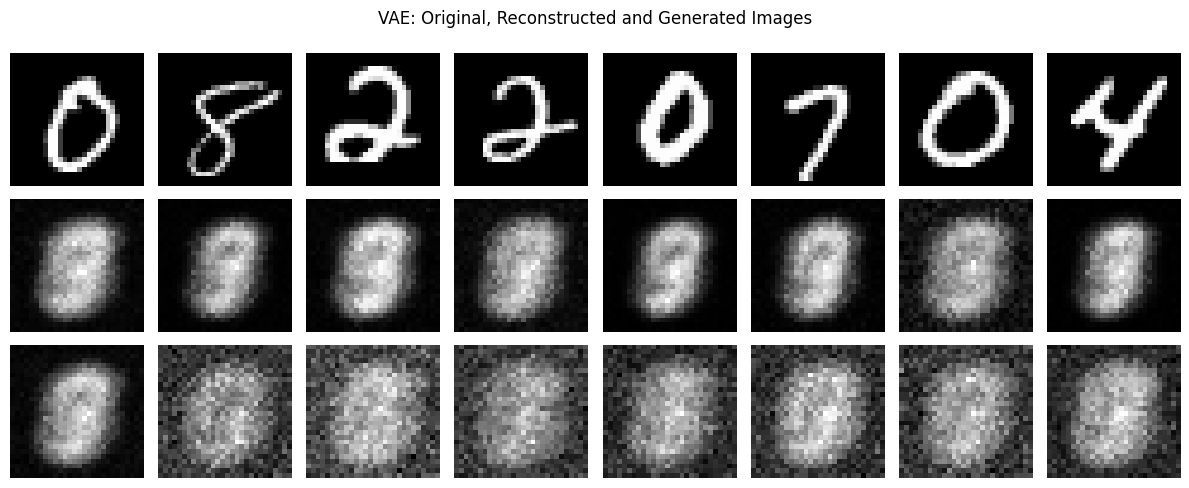

In [1]:

import torch
import torch.nn as nn
import torch.optim as optim
import torchvision
import torchvision.transforms as transforms
import matplotlib.pyplot as plt

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

transform = transforms.ToTensor()
dataset = torchvision.datasets.MNIST(
    root="./data", train=True, download=True, transform=transform
)
dataset = torch.utils.data.Subset(dataset, range(2000))
loader = torch.utils.data.DataLoader(dataset, batch_size=128, shuffle=True)

class VAE(nn.Module):
    def __init__(self):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(784, 256),
            nn.ReLU()
        )
        self.mu = nn.Linear(256, 20)
        self.logvar = nn.Linear(256, 20)
        self.decoder = nn.Sequential(
            nn.Linear(20, 256),
            nn.ReLU(),
            nn.Linear(256, 784),
            nn.Sigmoid()
        )

    def forward(self, x):
        x = self.encoder(x.view(-1, 784))
        mu = self.mu(x)
        logvar = self.logvar(x)
        std = torch.exp(0.5 * logvar)
        z = mu + std * torch.randn_like(std)
        reconstructed = self.decoder(z)
        return reconstructed, mu, logvar

model = VAE().to(device)
optimizer = optim.Adam(model.parameters(), lr=0.001)

for epoch in range(3):
    total_loss = 0
    model.train()

    for images, _ in loader:
        images = images.to(device)
        reconstructed, mu, logvar = model(images)

        reconstruction_loss = nn.functional.binary_cross_entropy(
            reconstructed, images.view(-1, 784), reduction="sum"
        )
        kl_loss = -0.5 * torch.sum(
            1 + logvar - mu.pow(2) - logvar.exp()
        )
        loss = reconstruction_loss + kl_loss

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        total_loss += loss.item()

    print(f"Epoch {epoch+1}, Loss: {total_loss/len(dataset):.2f}")

model.eval()

with torch.no_grad():
    test_images, _ = next(iter(loader))
    test_images = test_images[:8].to(device)
    reconstructed, _, _ = model(test_images)

    generated = model.decoder(
        torch.randn(8, 20, device=device)
    ).view(-1, 1, 28, 28)

fig, axes = plt.subplots(3, 8, figsize=(12, 5))

for i in range(8):
    axes[0, i].imshow(test_images[i].cpu().squeeze(), cmap="gray")
    axes[1, i].imshow(reconstructed[i].view(28, 28).cpu(), cmap="gray")
    axes[2, i].imshow(generated[i].cpu().squeeze(), cmap="gray")

    for j in range(3):
        axes[j, i].axis("off")

axes[0, 0].set_ylabel("Original")
axes[1, 0].set_ylabel("Reconstructed")
axes[2, 0].set_ylabel("Generated")

plt.suptitle("VAE: Original, Reconstructed and Generated Images")
plt.tight_layout()
plt.show()
